# Mejoras YOLOv10-S - dataset pills-sxdht

En el baseline (`baseline_yolov10.ipynb`) el TIDE nos dio que casi todo lo que se pierde del mAP50-95 es por **localizacion**: el modelo encuentra las pastillas y acierta la clase, pero las cajas no quedan del todo ajustadas (falla a partir de IoU 0.8). Por eso las mejoras intentan ajustar mejor las cajas:

| exp | cambio | por que |
|---|---|---|
| E1 | `epochs=200` | en las curvas del baseline el mAP de val seguia subiendo al final |
| E2 | `box=10, dfl=2` | darle mas peso a la parte de la loss que ajusta la caja |
| E3 | `imgsz=960` | con mas resolucion se ven mejor los bordes de las pastillas |
| E4 | TTA: imagen normal + volteada, juntando las cajas con WBF | la media de las dos cajas deberia quedar mas cerca de la real. No hay que entrenar |
| E5 | E1 + E2 + E3 juntos | ver si las mejoras se suman |

- De E1 a E4 cada experimento cambia solo una cosa respecto al baseline. E5 las junta.
- Para elegir miramos val. Test solo al final, con el baseline y el modelo final.
- Medimos todo con `mapviz.py` y score minimo 0.05, igual que en Faster R-CNN, para poder comparar los dos.
- `seed=0` en todo.

Lo ejecutamos en Kaggle con GPU T4. Hay que subir como dataset `mapviz.py` y el `best.pt` del baseline.

In [3]:
import shutil, sys, glob, os

# busca best.pt y mapviz.py en /kaggle/input y los copia (best.pt pasa a llamarse baseline.pt)
best = glob.glob('/kaggle/input/**/best.pt', recursive=True)[0]
mapviz = glob.glob('/kaggle/input/**/mapviz.py', recursive=True)[0]
print(best, mapviz)

shutil.copy(best, '/kaggle/working/baseline.pt')
shutil.copy(mapviz, '/kaggle/working/mapviz.py')

os.chdir('/kaggle/working')
sys.path.append('/kaggle/working')

/kaggle/input/datasets/martinhohd/datosss/best.pt /kaggle/input/datasets/martinhohd/datosss/mapviz.py


In [4]:
!pip install -q ultralytics==8.4.219 datasets ensemble_boxes

In [5]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion
from IPython.display import Image, display
import mapviz as mv

SEED = 0
CONF = 0.05  # score minimo, el mismo que en Faster R-CNN
DATA_DIR = Path("data/pills_yolo")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Dataset

Igual que en el baseline: las mismas 7 clases y las mismas imagenes.

In [6]:
ds = load_dataset("Francesco/pills-sxdht")

# nombres de las clases (cambia segun la version de datasets)
objs = ds["train"].features["objects"]
if hasattr(objs, "feature"):
    clases = objs.feature["category"].names  # datasets 3.x
else:
    clases = objs["category"].feature.names  # datasets 4.x (colab)

print(ds)
print(clases)

README.md:   0%|          | 0.00/3.51k [00:00<?, ?B/s]

data/train-00000-of-00001-d15b632ebb4ea5(…): reconstructing file:   0%|          |  0.00B / 17.1MB            

data/train-00000-of-00001-d15b632ebb4ea5(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-d6f6f66b7(…): reconstructing file:   0%|          |  0.00B / 2.64MB            

data/validation-00000-of-00001-d6f6f66b7(…): downloading bytes:           |  0.00B            

data/test-00000-of-00001-1afd43b66cacbc9(…): reconstructing file:   0%|          |  0.00B / 4.87MB            

data/test-00000-of-00001-1afd43b66cacbc9(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 316
    })
    validation: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 45
    })
    test: Dataset({
        features: ['image_id', 'image', 'width', 'height', 'objects'],
        num_rows: 90
    })
})
['pills', 'Cipro 500', 'Ibuphil 600 mg', 'Ibuphil Cold 400-60', 'Xyzall 5mg', 'blue', 'pink', 'red', 'white']


In [7]:
import shutil

quitar = ["pills", "Ibuphil 600 mg"]
clases_orig = clases
clases = [n for n in clases_orig if n not in quitar]
nuevo_id = {clases_orig.index(n): i for i, n in enumerate(clases)}  # id original -> id nuevo
print(clases)
print(nuevo_id)

shutil.rmtree(DATA_DIR, ignore_errors=True)  # por si habia una conversion anterior

splits = {"train": "train", "validation": "val", "test": "test"}

for split_hf, split_yolo in splits.items():
    (DATA_DIR / "images" / split_yolo).mkdir(parents=True, exist_ok=True)
    (DATA_DIR / "labels" / split_yolo).mkdir(parents=True, exist_ok=True)

    n = 0
    for ej in ds[split_hf]:
        cats = ej["objects"]["category"]
        if any(clases_orig[c] in quitar for c in cats):
            print("  quitamos image_id", ej["image_id"], "de", split_hf)
            continue

        nombre = str(ej["image_id"])
        ej["image"].convert("RGB").save(DATA_DIR / "images" / split_yolo / (nombre + ".jpg"))

        W, H = ej["width"], ej["height"]
        lineas = []
        for (x, y, w, h), c in zip(ej["objects"]["bbox"], cats):
            cx = (x + w / 2) / W
            cy = (y + h / 2) / H
            lineas.append(f"{nuevo_id[c]} {cx} {cy} {w / W} {h / H}")
        with open(DATA_DIR / "labels" / split_yolo / (nombre + ".txt"), "w") as f:
            f.write("\n".join(lineas))
        n += 1

    print(split_hf, n, "imagenes")

# yaml del dataset
with open(DATA_DIR / "data.yaml", "w") as f:
    f.write(f"path: {DATA_DIR.resolve().as_posix()}\n")
    f.write("train: images/train\nval: images/val\ntest: images/test\n")
    f.write("names:\n")
    for i, n in enumerate(clases):
        f.write(f"  {i}: '{n}'\n")

print(open(DATA_DIR / "data.yaml").read())

['Cipro 500', 'Ibuphil Cold 400-60', 'Xyzall 5mg', 'blue', 'pink', 'red', 'white']
{1: 0, 3: 1, 4: 2, 5: 3, 6: 4, 7: 5, 8: 6}
  quitamos image_id 12 de train
train 315 imagenes
validation 45 imagenes
  quitamos image_id 61 de test
test 89 imagenes
path: /kaggle/working/data/pills_yolo
train: images/train
val: images/val
test: images/test
names:
  0: 'Cipro 500'
  1: 'Ibuphil Cold 400-60'
  2: 'Xyzall 5mg'
  3: 'blue'
  4: 'pink'
  5: 'red'
  6: 'white'



## Como medimos

`predecir` pasa el modelo por todas las imagenes de val o test y devuelve las cajas reales y las predichas en el formato de `mapviz`, para sacar el mAP50 y el mAP50-95 con `mv.map50` y `mv.map_coco`. El `best.pt` de cada entrenamiento lo sigue eligiendo ultralytics con su mAP, pero todo lo demas lo medimos con mapviz.

Tambien devuelve el tiempo por imagen (lo que da ultralytics en `r.speed`). Usamos la mediana porque la primera imagen siempre tarda mas.

Con `tta=True` hace el E4: predice la imagen normal y la volteada, a las cajas de la volteada les deshace el volteo y junta las dos con WBF, que hace la media de las cajas de la misma pastilla. Lo hacemos a mano porque con YOLOv10 el `augment=True` de ultralytics no funciona.

In [8]:
def predecir(modelo, split, tta=False):
    # devuelve las cajas reales, las predichas (formato de mapviz) y los ms por imagen
    gts, preds, tiempos = [], [], []
    for f in sorted((DATA_DIR / "images" / split).glob("*.jpg")):
        img = cv2.imread(str(f))
        H, W = img.shape[:2]

        for linea in open(DATA_DIR / "labels" / split / (f.stem + ".txt")).read().splitlines():
            c, cx, cy, w, h = linea.split()
            cx, cy, w, h = float(cx) * W, float(cy) * H, float(w) * W, float(h) * H
            gts.append(dict(img=f.stem, cls=clases[int(c)], box=(cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2)))

        r = modelo.predict(img, conf=CONF, verbose=False)[0]
        cajas = r.boxes.xyxyn.cpu().numpy()  # normalizadas entre 0 y 1, es lo que pide WBF
        scores = r.boxes.conf.cpu().numpy()
        cls = r.boxes.cls.cpu().numpy()
        ms = sum(r.speed.values())

        if tta:
            r2 = modelo.predict(cv2.flip(img, 1), conf=CONF, verbose=False)[0]
            cajas2 = r2.boxes.xyxyn.cpu().numpy()
            cajas2[:, [0, 2]] = 1 - cajas2[:, [2, 0]]  # deshacer el volteo: x1 = 1 - x2, x2 = 1 - x1
            cajas, scores, cls = weighted_boxes_fusion([cajas, cajas2],
                                                       [scores, r2.boxes.conf.cpu().numpy()],
                                                       [cls, r2.boxes.cls.cpu().numpy()],
                                                       iou_thr=0.55, skip_box_thr=CONF)
            ms += sum(r2.speed.values())
        tiempos.append(ms)

        for b, s, c in zip(cajas, scores, cls):
            preds.append(dict(img=f.stem, cls=clases[int(c)], box=b * [W, H, W, H], score=float(s)))
    return gts, preds, np.median(tiempos)

## Baseline de referencia

No lo reentrenamos, cargamos su best.pt y lo medimos en val igual que los experimentos.

In [9]:
resultados = {}

def evaluar(nombre, modelo):
    # mAP en val con mapviz (no hace falta pasar imgsz, el modelo ya lo guarda)
    gts, preds, ms = predecir(modelo, "val")
    resultados[nombre] = [mv.map50(gts, preds), mv.map_coco(gts, preds), ms]
    print(nombre, " mAP50:", round(resultados[nombre][0], 3), " mAP50-95:", round(resultados[nombre][1], 3),
          f" {ms:.1f} ms/img")

baseline = YOLO("baseline.pt")
evaluar("baseline", baseline)

baseline  mAP50: 0.97  mAP50-95: 0.905  12.6 ms/img


## E1: 200 epocas

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/pills_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/200       5.6G     0.8419      5.423     0.9909         13        640: 100% ━━━━━━━━━━━━ 20/20 4.4it/s 4.5s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 5.2it/s 0.4s0.9s
                   all         45         47      0.563      0.322      0.433      0.341

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/200      5.62G     0.8867       2.98      1.013         17        640: 100% ━━━━━━━━━━━━ 20/20 4.4it/s 4.5s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.9it/s 0.4s1.0s
                   all         45         47      0.463      0.506      0.472      0.377

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/200      5.62G     0.8858      2.074      1.034         22        640: 100% ━━━━━━━━━━━━ 20/20 4.4it/s 4.5s0.2s
                 Class     Images  Instances  

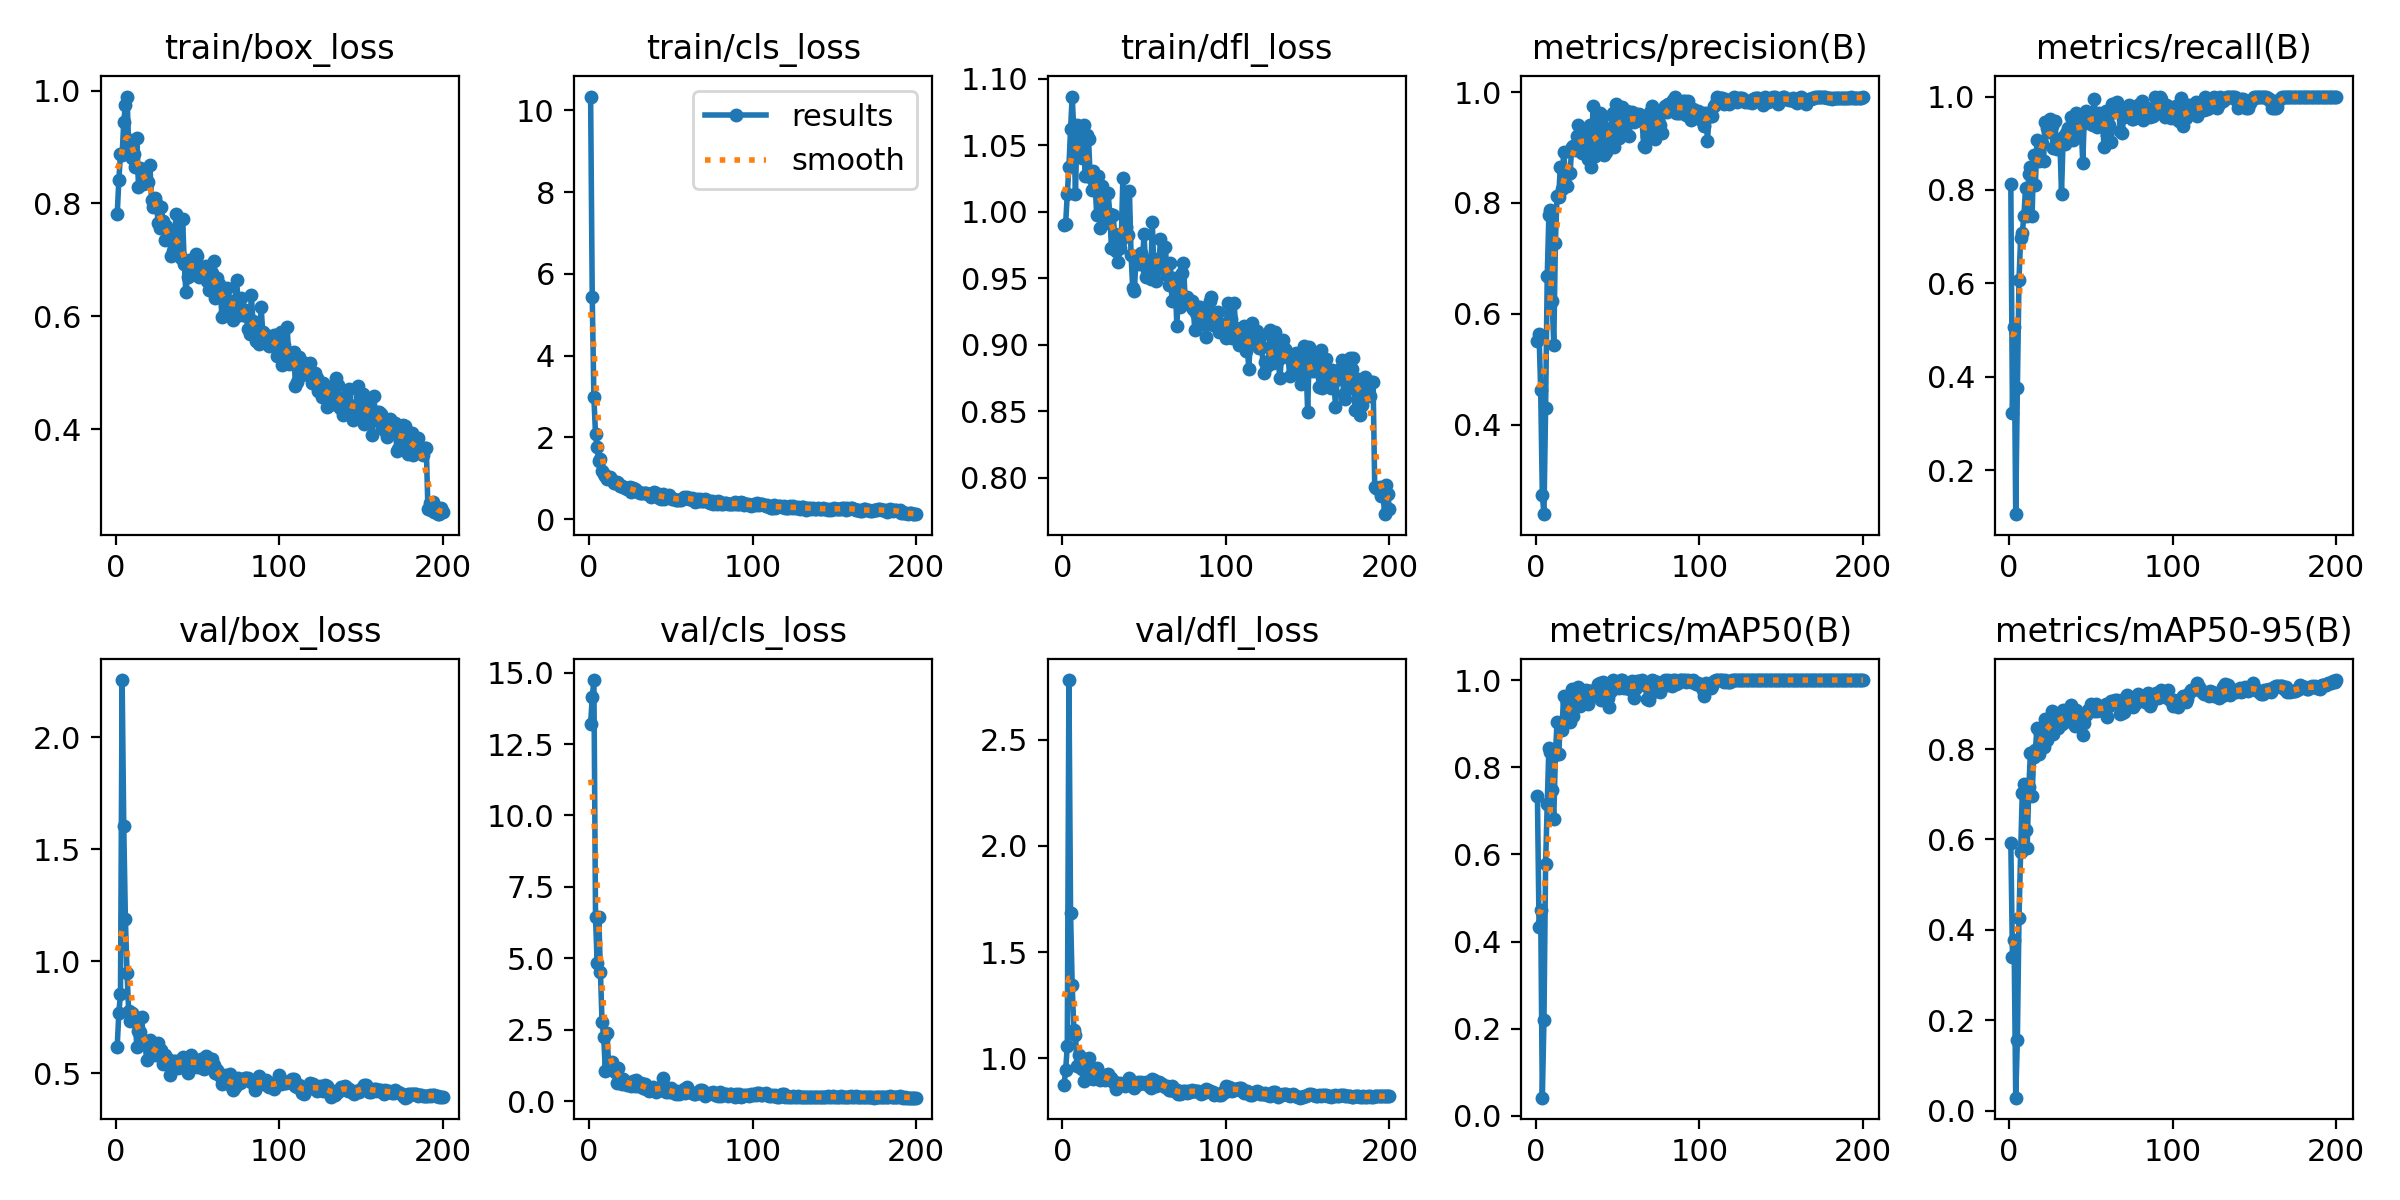

In [10]:
e1 = YOLO("yolov10s.pt")
e1.train(data=str(DATA_DIR / "data.yaml"), seed=SEED, name="e1_epochs200", epochs=200)
carpeta_e1 = Path(e1.trainer.save_dir)

e1 = YOLO(carpeta_e1 / "weights" / "best.pt")
evaluar("E1 epochs=200", e1)

# curvas: ver si con 200 epocas ya se estabiliza
display(Image(filename=carpeta_e1 / "results.png", width=900))

## E2: mas peso a la loss de la caja

In [11]:
e2 = YOLO("yolov10s.pt")
e2.train(data=str(DATA_DIR / "data.yaml"), seed=SEED, name="e2_box10_dfl2", box=10, dfl=2)

e2 = YOLO(Path(e2.trainer.save_dir) / "weights" / "best.pt")
evaluar("E2 box=10 dfl=2", e2)

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=10, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/pills_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=2, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=0.9

## E3: mas resolucion

In [12]:
e3 = YOLO("yolov10s.pt")
e3.train(data=str(DATA_DIR / "data.yaml"), seed=SEED, name="e3_imgsz960", imgsz=960)

e3 = YOLO(Path(e3.trainer.save_dir) / "weights" / "best.pt")
evaluar("E3 imgsz=960", e3)

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/pills_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=

## E5: todo junto

Juntamos los tres cambios de entrenamiento (E1 + E2 + E3) para ver si las mejoras se suman.

In [13]:
e5 = YOLO("yolov10s.pt")
e5.train(data=str(DATA_DIR / "data.yaml"), seed=SEED, name="e5_todo", epochs=200, box=10, dfl=2, imgsz=960)

e5 = YOLO(Path(e5.trainer.save_dir) / "weights" / "best.pt")
evaluar("E5 todo junto", e5)

New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.219 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=10, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/pills_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=2, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10s.pt, momentum=0.9

## Comparacion en val

Hay que tener en cuenta que val solo tiene 45 imagenes y que en el baseline el mAP de val sube y baja unas 0.01 entre epocas, asi que diferencias mas pequeñas pueden ser casualidad.

                 mAP50  mAP50-95  ms/img  dif mAP50-95
baseline         0.970     0.905  12.578         0.000
E1 epochs=200    1.000     0.944  13.202         0.039
E2 box=10 dfl=2  1.000     0.924  13.238         0.020
E3 imgsz=960     0.997     0.917  29.182         0.013
E5 todo junto    1.000     0.919  29.369         0.015


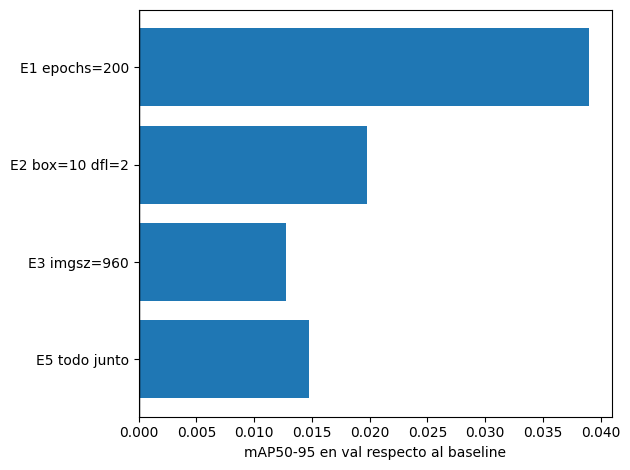

In [14]:
tabla = pd.DataFrame(resultados, index=["mAP50", "mAP50-95", "ms/img"]).T
tabla["dif mAP50-95"] = tabla["mAP50-95"] - tabla.loc["baseline", "mAP50-95"]
print(tabla.round(3))

dif = tabla["dif mAP50-95"].drop("baseline")
plt.barh(dif.index, dif.values)
plt.axvline(0, color="black", lw=1)
plt.xlabel("mAP50-95 en val respecto al baseline")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## E4: TTA con volteo

Como no hay que entrenar, lo probamos en val con todos los modelos, para ver si ayuda siempre.

In [15]:
modelos = {"baseline": baseline, "E1 epochs=200": e1, "E2 box=10 dfl=2": e2, "E3 imgsz=960": e3, "E5 todo junto": e5}

filas = {}
for nombre, modelo in modelos.items():
    gts, preds, ms = predecir(modelo, "val", tta=True)
    filas[nombre] = [resultados[nombre][1], mv.map_coco(gts, preds), resultados[nombre][2], ms]

tabla_tta = pd.DataFrame(filas, index=["sin TTA", "con TTA", "ms sin TTA", "ms con TTA"]).T
print("mAP50-95 en val")
print(tabla_tta.round(3))

mAP50-95 en val
                 sin TTA  con TTA  ms sin TTA  ms con TTA
baseline           0.905    0.915      12.578      26.706
E1 epochs=200      0.944    0.946      13.202      26.745
E2 box=10 dfl=2    0.924    0.932      13.238      26.754
E3 imgsz=960       0.917    0.929      29.182      59.069
E5 todo junto      0.919    0.925      29.369      59.183


## Modelo final

Nos quedamos con el modelo (con o sin TTA) que mas mAP50-95 da en val.

In [16]:
mejor, usar_tta, mejor_map = None, False, 0
for nombre in modelos:
    for tta, columna in [(False, "sin TTA"), (True, "con TTA")]:
        if tabla_tta.loc[nombre, columna] > mejor_map:
            mejor, usar_tta, mejor_map = nombre, tta, tabla_tta.loc[nombre, columna]

final = modelos[mejor]
print("modelo final:", mejor, "con TTA" if usar_tta else "sin TTA", " mAP50-95 en val:", round(mejor_map, 3))

modelo final: E1 epochs=200 con TTA  mAP50-95 en val: 0.946


## Evaluacion en test

Ahora si usamos test, solo con el baseline y el modelo final (con y sin TTA). Estos son los numeros que comparamos con Faster R-CNN.

In [17]:
filas = {}
for nombre, modelo, tta in [("baseline", baseline, False), ("final", final, False), ("final + TTA", final, True)]:
    gts, preds, ms = predecir(modelo, "test", tta=tta)
    filas[nombre] = [mv.map50(gts, preds), mv.map_coco(gts, preds), ms]

tabla_test = pd.DataFrame(filas, index=["mAP50", "mAP50-95", "ms/img"]).T
print(tabla_test.round(3))

             mAP50  mAP50-95  ms/img
baseline     0.987     0.906  13.198
final        0.976     0.894  13.311
final + TTA  0.976     0.902  26.959


## Analisis TIDE antes y despues

El mismo TIDE que en el baseline (media de los 10 umbrales de IoU), para ver si ha bajado el error de localizacion. Lo hacemos sin TTA para comparar los dos modelos tal cual.

Despues miramos tambien cuantas cajas tienen la clase mal, porque es lo que cambia el mAP50.

localizacion    baseline 0.081   final 0.085
clasificacion   baseline 0.001   final 0.009
duplicados      baseline 0.000   final 0.000
fondo           baseline 0.000   final 0.000
no detectadas   baseline 0.009   final 0.009


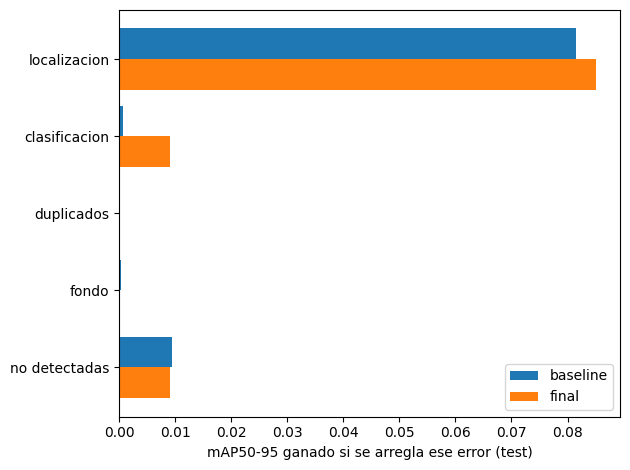

In [18]:
umbrales = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
tipos = ["loc", "cls", "dup", "bg", "miss"]
nombres = ["localizacion", "clasificacion", "duplicados", "fondo", "no detectadas"]

def tide(modelo):
    gts, preds, _ = predecir(modelo, "test")
    res = [mv.error_breakdown(gts, preds, iou_thr=t) for t in umbrales]
    return [np.mean([r["delta"][k] for r in res]) for k in tipos]

gan_base = tide(baseline)
gan_final = tide(final)
for n, a, b in zip(nombres, gan_base, gan_final):
    print(f"{n:15s} baseline {a:.3f}   final {b:.3f}")

y = np.arange(len(tipos))
plt.barh(y - 0.2, gan_base, 0.4, label="baseline")
plt.barh(y + 0.2, gan_final, 0.4, label="final")
plt.yticks(y, nombres)
plt.gca().invert_yaxis()
plt.xlabel("mAP50-95 ganado si se arregla ese error (test)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# esta celda la añadimos despues y la ejecutamos en local con los pesos de Kaggle
# cajas con la clase mal (pastilla bien encontrada a IoU 0.5 pero con otra clase) y su score
for split in ["val", "test"]:
    for nombre, modelo in [("baseline", baseline), ("final", final)]:
        gts, preds, _ = predecir(modelo, split)
        res = mv.error_breakdown(gts, preds, iou_thr=0.5)
        scores = [round(p["score"], 2) for p, t in zip(preds, res["types"]) if t == "cls"]
        print(f"{split:5s} {nombre:9s} cajas con la clase equivocada: {len(scores)}  scores: {sorted(scores, reverse=True)}")

val   baseline  cajas con la clase equivocada: 2  scores: [0.85, 0.36]
val   final     cajas con la clase equivocada: 0  scores: []
test  baseline  cajas con la clase equivocada: 3  scores: [0.86, 0.34, 0.09]
test  final     cajas con la clase equivocada: 3  scores: [0.97, 0.24, 0.2]


## Antes y despues en imagenes

A la izquierda, el mAP en test segun el umbral de IoU, y a la derecha el IoU de cada acierto con su caja real.

Debajo, las 4 pastillas de test donde mas cambia la caja (2 donde mejora el final y 2 donde empeora), con zoom.

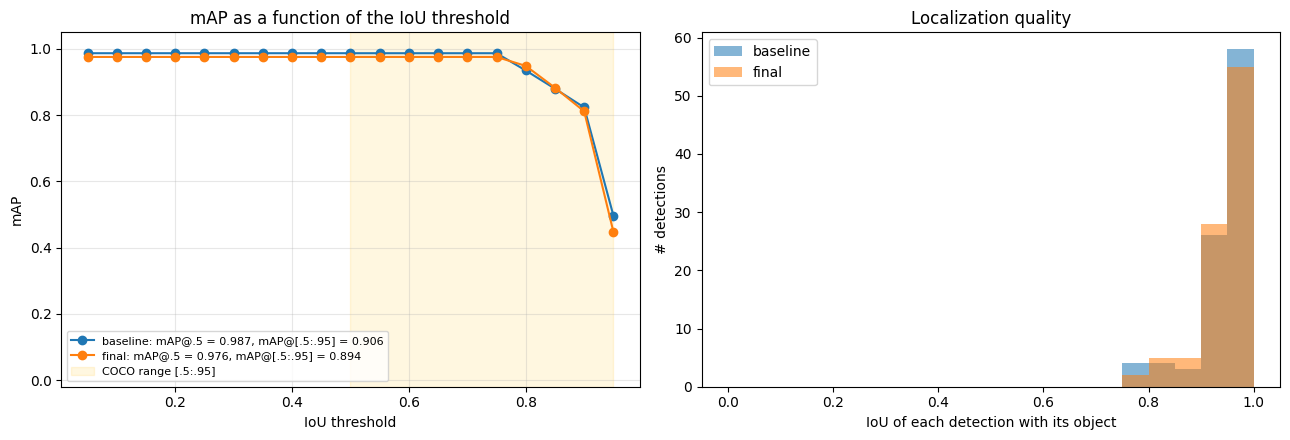

In [19]:
# mAP en test para cada umbral de IoU (izquierda) y el IoU de cada acierto (derecha)
gts, preds_base, _ = predecir(baseline, "test")
gts, preds_final, _ = predecir(final, "test")
mv.plot_ap_vs_iou(gts, {"baseline": preds_base, "final": preds_final})

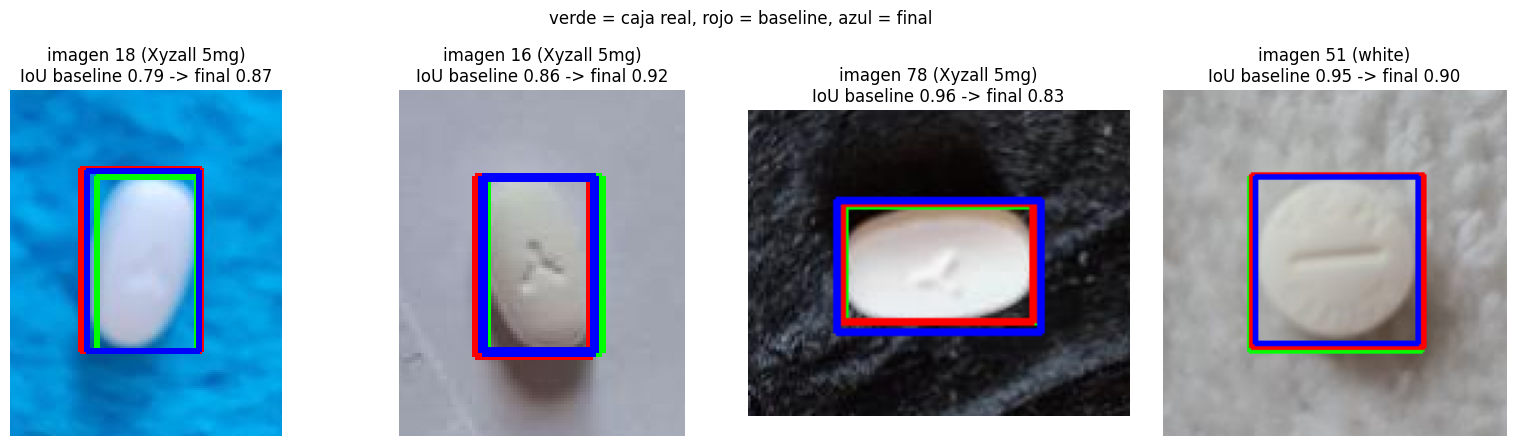

In [20]:
# las 4 pastillas de test donde mas cambia la caja: 2 donde mejora el final y 2 donde empeora
def mejor_caja(g, preds):
    # la prediccion de su clase (score > 0.3) que mas se parece a la caja real
    cands = [p for p in preds if p["img"] == g["img"] and p["cls"] == g["cls"] and p["score"] > 0.3]
    if not cands:
        return None, 0
    p = max(cands, key=lambda p: mv.iou(g["box"], p["box"]))
    return p["box"], mv.iou(g["box"], p["box"])

cambio = [mejor_caja(g, preds_final)[1] - mejor_caja(g, preds_base)[1] for g in gts]
orden = np.argsort(cambio)
elegidas = list(orden[::-1][:2]) + list(orden[:2])

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, i in zip(axes, elegidas):
    g = gts[i]
    img = cv2.imread(str(DATA_DIR / "images" / "test" / (g["img"] + ".jpg")))[:, :, ::-1].copy()
    caja_b, iou_b = mejor_caja(g, preds_base)
    caja_f, iou_f = mejor_caja(g, preds_final)
    for caja, color in [(g["box"], (0, 255, 0)), (caja_b, (255, 0, 0)), (caja_f, (0, 0, 255))]:
        if caja is not None:
            x1, y1, x2, y2 = map(int, caja)
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
    # zoom alrededor de la pastilla para que se vea la diferencia
    x1, y1, x2, y2 = map(int, g["box"])
    m = max(x2 - x1, y2 - y1) // 2
    ax.imshow(img[max(y1 - m, 0):y2 + m, max(x1 - m, 0):x2 + m])
    ax.set_title(f"imagen {g['img']} ({g['cls']})\nIoU baseline {iou_b:.2f} -> final {iou_f:.2f}")
    ax.axis("off")
plt.suptitle("verde = caja real, rojo = baseline, azul = final")
plt.tight_layout()
plt.show()

In [21]:
# comprimir los entrenamientos (pesos y graficas) para descargarlos desde la pestaña Output de Kaggle
shutil.make_archive("runs_mejoras", "zip", "runs")

'/kaggle/working/runs_mejoras.zip'

## Conclusiones

mAP50-95 con `mapviz`:

| modelo | val sin TTA | val con TTA | test sin TTA | test con TTA |
|---|---|---|---|---|
| baseline | 0.905 | 0.915 | 0.906 | |
| E1 epochs=200 | 0.944 | 0.946 | 0.894 | 0.902 |
| E2 box=10 dfl=2 | 0.924 | 0.932 | | |
| E3 imgsz=960 | 0.917 | 0.929 | | |
| E5 todo junto | 0.919 | 0.925 | | |

El modelo final es **E1 + TTA**, porque es el que mas da en val. En test solo probamos el baseline y el final.

- En val todas las mejoras ganan al baseline, la que mas E1 (+0.039).
- Juntarlas (E5) no suma: da menos que E1 solo y tarda mas del doble por la imagen a 960 (29 ms frente a 13).
- El TTA mejora un poco a todos en val y tambien al final en test (0.894 -> 0.902), pero duplica el tiempo (27 ms).
- En test el final no mejora al baseline (0.902 frente a 0.906): lo que ganaba E1 en val no se mantiene.

Por que creemos que pasa:
- Val y test son muy pequeños (47 y 97 pastillas). En val hay entre 5 y 8 pastillas por clase, asi que fallar una sola ya baja el mAP unos 0.02. Las diferencias en val son de 1 o 2 pastillas, y la de test (0.004) es menos de una.
- Se ve en la celda de errores de clase: en val el baseline tiene 2 cajas con la clase mal y E1 ninguna. En test los dos tienen 3, pero una del final tiene score 0.97 y por eso le quita mas mAP.
- La localizacion, que era lo que queriamos mejorar, no baja (TIDE 0.081 -> 0.085). En las imagenes de antes y despues el final mueve las cajas unos pocos pixeles, unas veces a mejor y otras a peor.
- Pensamos que el limite esta en las anotaciones: hay cajas que no estan bien ajustadas (como en la imagen 80) y a IoU 0.95 unos pocos pixeles ya cuentan como fallo.

Con mas tiempo probariamos varias semillas o validacion cruzada, porque con un val tan pequeño es dificil saber que mejora de verdad.

Para comparar con Faster R-CNN usamos los numeros de test: 0.906 el baseline y 0.902 el final, a 13 ms por imagen (27 con TTA).